[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_4_Regresion_Lineal_MolLogP.ipynb)

# Fase 4. Regresión lineal de MolLogP

En esta fase tomo MolLogP como variable dependiente y evalúo si otros descriptores moleculares ayudan a explicarlo. Calculo los 217 descriptores escalares de RDKit en la fase 2. Para que el modelo sea interpretable y no incluya demasiados predictores para el tamaño de la muestra, selecciono en entrenamiento hasta veinte descriptores asociados con MolLogP y retiro los que presentan correlación absoluta de Spearman de 0,90 o más. Reservo prueba para evaluar el resultado.

In [1]:
# Instalo statsmodels para obtener coeficientes, valores p y el estadístico F.
%pip -q install statsmodels


## 4.1. Lectura de los datos

Cargo los CSV preparados en la fase 2 desde el repositorio.

In [2]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
datos = dilist.merge(estructuras, on='CompoundName', how='left')  # Uno las etiquetas con el estado de búsqueda.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

He cargado los datos del repositorio: /workspace/scratch/b597cb51ba0f/run_outputs/datos_dili
Descriptores numéricos disponibles: 218


## 4.2. Preparación y ajuste

Primero reviso la correlación entre predictores con entrenamiento y retiro variables redundantes con correlación absoluta de Spearman de 0,90 o más. Ajusto la imputación y la estandarización solo con train; después aplico esas transformaciones a train y test.

Descriptores candidatos: 211
Candidatos con mayor asociación a MolLogP: 20
Descriptores que usaré: ['VSA_EState6', 'PEOE_VSA7', 'PEOE_VSA6', 'NHOHCount', 'SMR_VSA7', 'TPSA', 'fr_benzene', 'EState_VSA4', 'fr_NH2', 'VSA_EState7', 'VSA_EState8', 'SlogP_VSA5', 'EState_VSA7', 'EState_VSA1', 'SlogP_VSA1', 'PEOE_VSA1']
Predictores retirados por VIF: [('TPSA', np.float64(76.28469537131926)), ('EState_VSA1', np.float64(44.60005719657809)), ('NHOHCount', np.float64(31.034265619571777)), ('PEOE_VSA1', np.float64(12.102936415161006)), ('SlogP_VSA5', np.float64(10.313337943858407)), ('VSA_EState6', np.float64(5.57838684231414))]
Retiro iterativamente el VIF mayor hasta que queda en cinco o menos; es un umbral práctico, no universal.
                            OLS Regression Results                            
Dep. Variable:                MolLogP   R-squared:                       0.893
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squ

,descriptor,VIF
2,SMR_VSA7,4.47
9,SlogP_VSA1,4.24
3,fr_benzene,3.84
0,PEOE_VSA7,3.28
5,fr_NH2,2.86
1,PEOE_VSA6,2.82
7,VSA_EState8,1.83
6,VSA_EState7,1.82
4,EState_VSA4,1.51
8,EState_VSA7,1.36


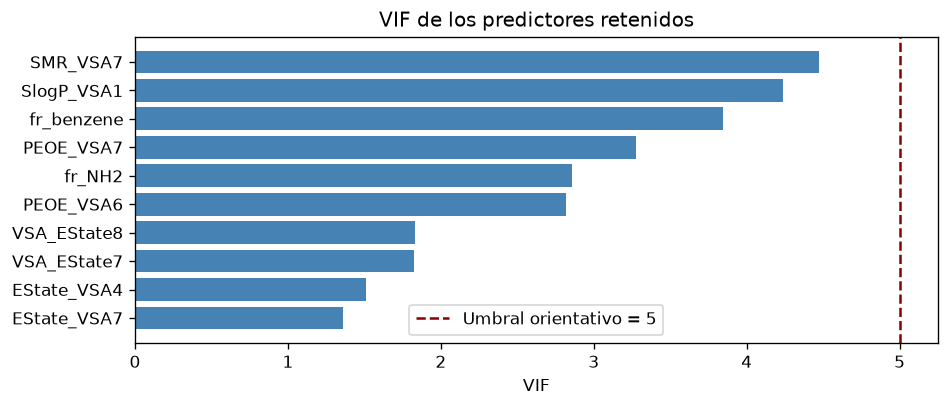

In [3]:
# Importo herramientas para imputar, estandarizar y ajustar una regresión lineal.
from sklearn.impute import SimpleImputer  # Completo posibles valores ausentes.
from sklearn.preprocessing import StandardScaler  # Estandarizo los predictores.
from statsmodels.api import OLS, add_constant  # Ajusto la regresión y añado el intercepto.
from statsmodels.stats.outliers_influence import variance_inflation_factor  # Calculo VIF de los predictores.

# Defino MolLogP como variable que quiero explicar.
respuesta = 'MolLogP'  # Selecciono la variable dependiente.
columnas_excluir = ['MolLogP', 'LipinskiViolations', 'DILI', 'DILIST_ID']  # Evito respuesta, su derivación y variables de identificación.
predictores = [variable for variable in DESCRIPTORES if variable not in columnas_excluir and train_df[variable].nunique(dropna=True) > 1]  # Uso descriptores no constantes.
print('Descriptores candidatos:', len(predictores))  # Informo el tamaño inicial del catálogo.

# Hago un cribado exploratorio de los descriptores asociados con MolLogP en train.
asociacion = train_df[predictores + [respuesta]].corr(method='spearman')[respuesta].drop(respuesta).dropna().abs().sort_values(ascending=False)  # Ordeno la asociación absoluta.
candidatos = asociacion.head(20).index.tolist()  # Limito el modelo a veinte candidatos.
print('Candidatos con mayor asociación a MolLogP:', len(candidatos))  # Muestro el número seleccionado.

# Retiro predictores redundantes dentro de los candidatos.
correlacion = train_df[candidatos].corr(method='spearman').abs()  # Calculo relaciones absolutas entre candidatos.
seleccionados = []  # Creo una lista para los predictores finales.
for variable in candidatos:  # Reviso los candidatos en orden de asociación.
    if not any(correlacion.loc[variable, otra] >= 0.90 for otra in seleccionados):  # Compruebo redundancia con los ya elegidos.
        seleccionados.append(variable)  # Conservo variables que no superan el límite.
print('Descriptores que usaré:', seleccionados)  # Informo las variables finales.

# Preparo respuesta e imputación usando solo entrenamiento.
y_train = train_df[respuesta]  # Tomo MolLogP de entrenamiento.
y_test = test_df[respuesta]  # Tomo MolLogP de prueba.
imputador = SimpleImputer(strategy='median')  # Creo imputación por mediana.
imputador.fit(train_df[seleccionados])  # Aprendo medianas solo con train.
X_train_imp = imputador.transform(train_df[seleccionados])  # Transformo los predictores de train.
X_test_imp = imputador.transform(test_df[seleccionados])  # Aplico medianas de train a test.
escalador = StandardScaler()  # Creo el estandarizador.
escalador.fit(X_train_imp)  # Aprendo medias y desviaciones solo con train.
X_train = pd.DataFrame(escalador.transform(X_train_imp), columns=seleccionados, index=train_df.index)  # Estandarizo train.
X_test = pd.DataFrame(escalador.transform(X_test_imp), columns=seleccionados, index=test_df.index)  # Transformo test con el mismo escalador.

# Ajusto el modelo lineal con entrenamiento.
# Compruebo colinealidad multivariante después del filtro por pares.
variables_retiradas_vif = []  # Guardo los predictores retirados por VIF alto.
while len(seleccionados) > 2:  # Mantengo al menos dos predictores.
    tabla_vif = pd.DataFrame({'descriptor': X_train.columns, 'VIF': [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]})  # Calculo VIF por predictor.
    if tabla_vif['VIF'].max() <= 5:  # Uso cinco como señal orientativa de colinealidad.
        break  # Paro cuando todos quedan bajo el límite.
    fila_maxima = tabla_vif['VIF'].idxmax()  # Localizo el mayor VIF.
    variable_retirada = tabla_vif.loc[fila_maxima, 'descriptor']  # Identifico el descriptor asociado.
    variables_retiradas_vif.append((variable_retirada, tabla_vif.loc[fila_maxima, 'VIF']))  # Registro el cambio.
    seleccionados.remove(variable_retirada)  # Retiro el predictor más redundante.
    X_train = X_train.drop(columns=variable_retirada)  # Quito la columna de train.
    X_test = X_test.drop(columns=variable_retirada)  # Aplico la misma selección a test.
tabla_vif = pd.DataFrame({'descriptor': X_train.columns, 'VIF': [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]})  # Calculo los VIF finales.
display(tabla_vif.sort_values('VIF', ascending=False).round(2))  # Muestro el diagnóstico final.

# Represento los VIF restantes y el umbral utilizado para decidir.
import matplotlib.pyplot as plt  # Dibujo el diagnóstico de colinealidad.
orden_vif = tabla_vif.sort_values('VIF')  # Ordeno las variables para facilitar la lectura.
fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(orden_vif))))  # Ajusto el alto al número de predictores.
ax.barh(orden_vif['descriptor'], orden_vif['VIF'], color='steelblue')  # Dibujo el VIF de cada descriptor.
ax.axvline(5, color='darkred', linestyle='--', label='Umbral orientativo = 5')  # Marco el umbral de revisión.
ax.set_xlabel('VIF')  # Etiqueto el eje.
ax.set_title('VIF de los predictores retenidos')  # Titulo el gráfico.
ax.legend()  # Identifico la línea de referencia.
plt.tight_layout()  # Ajusto etiquetas y márgenes.
plt.show()  # Muestro el diagnóstico visual.
print('Predictores retirados por VIF:', variables_retiradas_vif if variables_retiradas_vif else 'ninguno')  # Indico el efecto del diagnóstico.
print('Retiro iterativamente el VIF mayor hasta que queda en cinco o menos; es un umbral práctico, no universal.')  # Explico el criterio.

# Ajusto el modelo con los predictores que superaron los filtros.
modelo = OLS(y_train, add_constant(X_train, has_constant='add')).fit()  # Estimo coeficientes e inferencia.
print(modelo.summary())  # Muestro intercepto, coeficientes, R cuadrado, F y valores p.
print(f"El modelo explica {100 * modelo.rsquared:.1f}% de la variabilidad de MolLogP en train (R² = {modelo.rsquared:.3f}).")  # Interpreto el ajuste dentro de train.
print(f"La prueba F global tiene p = {modelo.f_pvalue:.3g}; la leo junto con el rendimiento en test.")  # Comento significancia global.
variables_p = modelo.pvalues.drop('const').loc[lambda valores: valores < 0.05].sort_values()  # Identifico predictores con p < 0,05.
print('Predictores con p < 0,05 en train:', list(variables_p.index) if len(variables_p) else 'ninguno')  # Resumo la inferencia.



## 4.3. Evaluación en prueba

Calculo R² y RMSE en los datos reservados. Los coeficientes representan el cambio esperado de MolLogP por una desviación estándar del predictor, manteniendo constantes los demás.

R² de prueba: 0.876
MSE de prueba: 1.566
RMSE de prueba: 1.251
La desviación estándar de MolLogP en test es 3.565; RMSE/desviación estándar = 0.35.
En test explica 87.6% de la variabilidad observada de MolLogP.
Los puntos alejados de cero corresponden a compuestos con mayor error; los reviso como diagnóstico y no los quito de test.


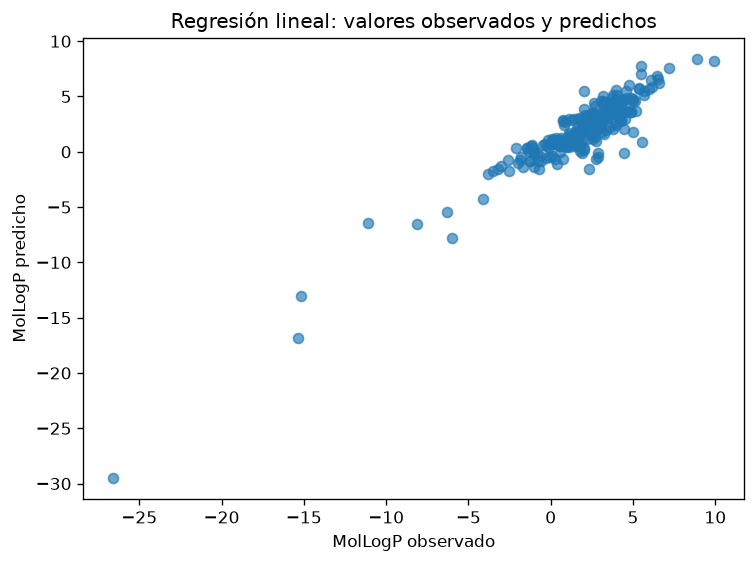

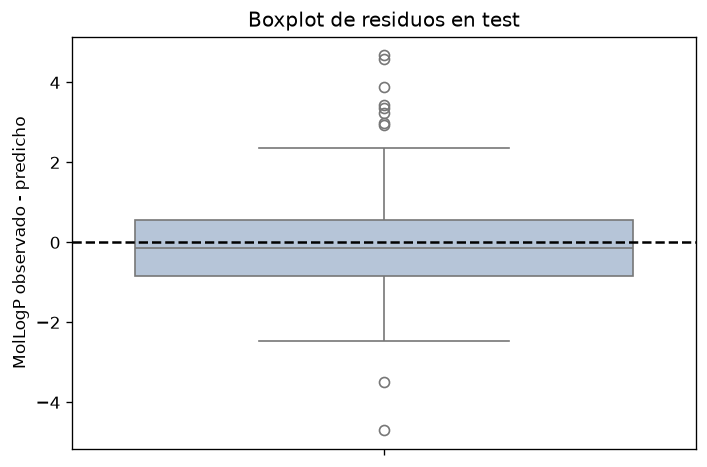

In [4]:
# Importo métricas para medir el error en el conjunto de prueba.
from sklearn.metrics import mean_squared_error, r2_score  # Calculo error cuadrático y R cuadrado.

# Predigo MolLogP para compuestos que no se usaron en el ajuste.
prediccion = modelo.predict(add_constant(X_test, has_constant='add'))  # Calculo valores predichos.
mse = mean_squared_error(y_test, prediccion)  # Calculo el error cuadrático medio.
rmse = np.sqrt(mse)  # Expreso el error en unidades de MolLogP.
r2_test = r2_score(y_test, prediccion)  # Calculo la proporción de varianza explicada en test.
print(f'R² de prueba: {r2_test:.3f}')  # Informo R cuadrado.
print(f'MSE de prueba: {mse:.3f}')  # Informo error cuadrático medio.
print(f'RMSE de prueba: {rmse:.3f}')  # Informo error típico aproximado.

# Comparo valores observados y predichos en una figura.
import matplotlib.pyplot as plt  # Importo gráficos.
import seaborn as sns  # Dibujo los residuos en un boxplot.
plt.scatter(y_test, prediccion, alpha=0.65)  # Dibujo observaciones y predicciones.
plt.xlabel('MolLogP observado')  # Etiqueto el eje horizontal.
plt.ylabel('MolLogP predicho')  # Etiqueto el eje vertical.
plt.title('Regresión lineal: valores observados y predichos')  # Titulo el gráfico.
plt.tight_layout()  # Ajusto los márgenes.
plt.show()  # Muestro la figura.

# Comparo el error de prueba con la dispersión de MolLogP.
print(f"La desviación estándar de MolLogP en test es {y_test.std():.3f}; RMSE/desviación estándar = {rmse / y_test.std():.2f}.")  # Pongo el RMSE en contexto.
if r2_test < 0:  # Compruebo si el modelo supera una predicción constante.
    print('R² negativo: en test predice peor que usar la media de MolLogP de train.')  # Interpreto un valor negativo.
else:  # Interpreto un R² no negativo.
    print(f"En test explica {100 * r2_test:.1f}% de la variabilidad observada de MolLogP.")  # Comento el rendimiento externo.

# Reviso la distribución de errores en el conjunto reservado.
residuos_test = y_test - prediccion  # Calculo observado menos predicho.
plt.figure(figsize=(6, 4))  # Creo una figura para el boxplot.
sns.boxplot(y=residuos_test, color='lightsteelblue', showfliers=True)  # Dibujo los residuos y sus extremos.
plt.axhline(0, color='black', linestyle='--')  # Marco el error nulo.
plt.title('Boxplot de residuos en test')  # Titulo el gráfico.
plt.ylabel('MolLogP observado - predicho')  # Etiqueto el error.
plt.tight_layout()  # Ajusto la figura.
plt.show()  # Muestro el boxplot.
print('Los puntos alejados de cero corresponden a compuestos con mayor error; los reviso como diagnóstico y no los quito de test.')  # Interpreto los extremos.



## Lectura del modelo

Interpreto el VIF como diagnóstico de redundancia multivariante; los coeficientes y valores p describen asociaciones en train, mientras R² y RMSE de test valoran la predicción fuera de muestra. Retiro iterativamente el VIF mayor hasta cinco o menos, como criterio orientativo. Los coeficientes corresponden a una desviación estándar del predictor. El boxplot de residuos localiza errores grandes, pero no elimino registros de test. MolLogP es una propiedad fisicoquímica; este ejercicio no predice por sí mismo lesión hepática.
